In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

In [2]:
df = pd.read_csv("all_matches_games_ids.csv")

df.head()

,Tournament,Tournament ID,Stage,Stage ID,Match Type,Match Type ID,Match Name,Match ID,Map,Game ID,Year
0,Valorant Champions 2021,449,Group Stage,945,Opening (D),8272.0,Vision Strikers vs FULL SENSE,51282,Haven,57948.0,2021
1,Valorant Champions 2021,449,Group Stage,945,Opening (D),8272.0,Vision Strikers vs FULL SENSE,51282,Breeze,57949.0,2021
2,Valorant Champions 2021,449,Group Stage,945,Opening (C),8268.0,Team Vikings vs Crazy Raccoon,51278,Icebox,57936.0,2021
3,Valorant Champions 2021,449,Group Stage,945,Opening (C),8268.0,Team Vikings vs Crazy Raccoon,51278,Haven,57937.0,2021
4,Valorant Champions 2021,449,Group Stage,945,Opening (D),8272.0,FNATIC vs Cloud9,51283,Icebox,57951.0,2021


In [3]:
df.shape

(27450, 11)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27450 entries, 0 to 27449
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Tournament     27450 non-null  object 
 1   Tournament ID  27450 non-null  int64  
 2   Stage          27450 non-null  object 
 3   Stage ID       27450 non-null  int64  
 4   Match Type     27450 non-null  object 
 5   Match Type ID  27375 non-null  float64
 6   Match Name     27450 non-null  object 
 7   Match ID       27450 non-null  int64  
 8   Map            27448 non-null  object 
 9   Game ID        27449 non-null  float64
 10  Year           27450 non-null  int64  
dtypes: float64(2), int64(4), object(5)
memory usage: 2.3+ MB


In [5]:
df.columns

Index(['Tournament', 'Tournament ID', 'Stage', 'Stage ID', 'Match Type',
       'Match Type ID', 'Match Name', 'Match ID', 'Map', 'Game ID', 'Year'],
      dtype='object')

In [6]:
df.head()

,Tournament,Tournament ID,Stage,Stage ID,Match Type,Match Type ID,Match Name,Match ID,Map,Game ID,Year
0,Valorant Champions 2021,449,Group Stage,945,Opening (D),8272.0,Vision Strikers vs FULL SENSE,51282,Haven,57948.0,2021
1,Valorant Champions 2021,449,Group Stage,945,Opening (D),8272.0,Vision Strikers vs FULL SENSE,51282,Breeze,57949.0,2021
2,Valorant Champions 2021,449,Group Stage,945,Opening (C),8268.0,Team Vikings vs Crazy Raccoon,51278,Icebox,57936.0,2021
3,Valorant Champions 2021,449,Group Stage,945,Opening (C),8268.0,Team Vikings vs Crazy Raccoon,51278,Haven,57937.0,2021
4,Valorant Champions 2021,449,Group Stage,945,Opening (D),8272.0,FNATIC vs Cloud9,51283,Icebox,57951.0,2021


In [7]:
df.shape

(27450, 11)

In [8]:
df.isnull().sum()

Tournament        0
Tournament ID     0
Stage             0
Stage ID          0
Match Type        0
Match Type ID    75
Match Name        0
Match ID          0
Map               2
Game ID           1
Year              0
dtype: int64

In [9]:
df.columns.tolist()

['Tournament',
 'Tournament ID',
 'Stage',
 'Stage ID',
 'Match Type',
 'Match Type ID',
 'Match Name',
 'Match ID',
 'Map',
 'Game ID',
 'Year']

In [10]:
df.tail()

,Tournament,Tournament ID,Stage,Stage ID,Match Type,Match Type ID,Match Name,Match ID,Map,Game ID,Year
27445,VCT 2026: China Kickoff,2685,Main Event,0,Middle Final,35570.0,Xi Lai Gaming vs Bilibili Gaming,598941,Split,245264.0,2026
27446,VCT 2026: China Kickoff,2685,Main Event,0,Lower Final,35576.0,Bilibili Gaming vs EDward Gaming,598950,Pearl,245289.0,2026
27447,VCT 2026: China Kickoff,2685,Main Event,0,Lower Final,35576.0,Bilibili Gaming vs EDward Gaming,598950,Haven,245290.0,2026
27448,VCT 2026: China Kickoff,2685,Main Event,0,Lower Final,35576.0,Bilibili Gaming vs EDward Gaming,598950,Abyss,245291.0,2026
27449,VCT 2026: China Kickoff,2685,Main Event,0,Lower Final,35576.0,Bilibili Gaming vs EDward Gaming,598950,Split,253654.0,2026


In [11]:
df_teams = pd.read_csv("all_teams_mapping.csv")

df_teams.head()

,Abbreviated,Full Name
0,VS,Vision Strikers
1,FS,FULL SENSE
2,VKS,Team Vikings
3,CR,Carleton Ravens
4,FNC,FNATIC


In [12]:
df_teams.columns.tolist()

['Abbreviated', 'Full Name']

In [13]:
df_team_ids = pd.read_csv("all_teams_ids.csv")

df_team_ids.head()

,Team,Team ID
0,Vision Strikers,198.0
1,FULL SENSE,4050.0
2,Team Vikings,420.0
3,Crazy Raccoon,277.0
4,FNATIC,2593.0


In [14]:
df_tournaments = pd.read_csv("all_tournaments_stages_match_types_ids.csv")

df_tournaments.head()

,Tournament,Tournament ID,Stage,Stage ID,Match Type,Match Type ID,Year
0,Champions Tour Asia-Pacific: Last Chance Quali...,560,All Stages,NaN,All Match Types,NaN,2021
1,Champions Tour Asia-Pacific: Last Chance Quali...,560,Main Event,1096.0,Upper Round 1,NaN,2021
2,Champions Tour Asia-Pacific: Last Chance Quali...,560,Main Event,1096.0,Grand Final,7577.0,2021
3,Champions Tour Asia-Pacific: Last Chance Quali...,560,Main Event,1096.0,Lower Bracket Final,7576.0,2021
4,Champions Tour Asia-Pacific: Last Chance Quali...,560,Main Event,1096.0,Lower Bracket Round 1,7572.0,2021


In [15]:
df_tournaments.columns.tolist()

['Tournament',
 'Tournament ID',
 'Stage',
 'Stage ID',
 'Match Type',
 'Match Type ID',
 'Year']

In [16]:
import os

for root, dirs, files in os.walk("."):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

.\all_matches_games_ids.csv
.\all_players_ids.csv
.\all_teams_ids.csv
.\all_teams_mapping.csv
.\all_tournaments_stages_match_types_ids.csv
.\maps_scores.csv
.\overview.csv
.\.ipynb_checkpoints\all_matches_games_ids-checkpoint.csv
.\.ipynb_checkpoints\all_players_ids-checkpoint.csv
.\.ipynb_checkpoints\all_tournaments_stages_match_types_ids-checkpoint.csv


In [17]:
df_players = pd.read_csv("all_players_ids.csv")

df_players.head()

,Player,Player ID
0,MaKo,4462.0
1,stax,485.0
2,Rb,488.0
3,k1Ng,771.0
4,BuZz,804.0


In [18]:
df_tournaments.head()

,Tournament,Tournament ID,Stage,Stage ID,Match Type,Match Type ID,Year
0,Champions Tour Asia-Pacific: Last Chance Quali...,560,All Stages,NaN,All Match Types,NaN,2021
1,Champions Tour Asia-Pacific: Last Chance Quali...,560,Main Event,1096.0,Upper Round 1,NaN,2021
2,Champions Tour Asia-Pacific: Last Chance Quali...,560,Main Event,1096.0,Grand Final,7577.0,2021
3,Champions Tour Asia-Pacific: Last Chance Quali...,560,Main Event,1096.0,Lower Bracket Final,7576.0,2021
4,Champions Tour Asia-Pacific: Last Chance Quali...,560,Main Event,1096.0,Lower Bracket Round 1,7572.0,2021


In [19]:
df_scores_2025 = pd.read_csv("maps_scores.csv")
df_scores_2025.head()

,Tournament,Stage,Match Type,Match Name,Map,Team A,Team A Score,Team A Attacker Score,Team A Defender Score,Team A Overtime Score,Team B,Team B Score,Team B Attacker Score,Team B Defender Score,Team B Overtime Score,Duration
0,Valorant Champions 2025,Group Stage,Opening (A),Paper Rex vs Xi Lai Gaming,Bind,Paper Rex,13,6,7,NaN,Xi Lai Gaming,9,3,6,NaN,48:56
1,Valorant Champions 2025,Group Stage,Opening (A),Paper Rex vs Xi Lai Gaming,Sunset,Paper Rex,13,8,5,NaN,Xi Lai Gaming,5,1,4,NaN,39:04
2,Valorant Champions 2025,Group Stage,Opening (A),GIANTX vs Sentinels,Corrode,GIANTX,6,6,0,NaN,Sentinels,13,7,6,NaN,41:17
3,Valorant Champions 2025,Group Stage,Opening (A),GIANTX vs Sentinels,Sunset,GIANTX,13,10,3,NaN,Sentinels,4,2,2,NaN,38:15
4,Valorant Champions 2025,Group Stage,Opening (A),GIANTX vs Sentinels,Haven,GIANTX,13,4,9,NaN,Sentinels,9,1,8,NaN,51:34


In [20]:
df_scores_2025.shape

(1277, 16)

In [21]:
df_scores_2025.isnull().sum()

Tournament                  0
Stage                       0
Match Type                  0
Match Name                  0
Map                         0
Team A                      0
Team A Score                0
Team A Attacker Score       0
Team A Defender Score       0
Team A Overtime Score    1132
Team B                      0
Team B Score                0
Team B Attacker Score       0
Team B Defender Score       0
Team B Overtime Score    1132
Duration                   98
dtype: int64

In [22]:
(df_scores_2025["Team A Score"] == df_scores_2025["Team B Score"]).sum()

np.int64(0)

In [23]:
df_scores_2025["Winner"] = np.where(
    df_scores_2025["Team A Score"] > df_scores_2025["Team B Score"],
    df_scores_2025["Team A"],
    df_scores_2025["Team B"]
)
df_scores_2025[["Team A", "Team A Score", "Team B", "Team B Score", "Winner"]].head()

,Team A,Team A Score,Team B,Team B Score,Winner
0,Paper Rex,13,Xi Lai Gaming,9,Paper Rex
1,Paper Rex,13,Xi Lai Gaming,5,Paper Rex
2,GIANTX,6,Sentinels,13,Sentinels
3,GIANTX,13,Sentinels,4,GIANTX
4,GIANTX,13,Sentinels,9,GIANTX


In [24]:
df_scores_2025["Team A Win"] = (df_scores_2025["Team A Score"] > df_scores_2025["Team B Score"]).astype(int)
df_scores_2025["Team A Win"].value_counts()

Team A Win
1    652
0    625
Name: count, dtype: int64

In [25]:
features = ["Tournament", "Stage", "Match Type", "Map", "Team A", "Team B"]
X = df_scores_2025[features]
y = df_scores_2025["Team A Win"]
X.head()

,Tournament,Stage,Match Type,Map,Team A,Team B
0,Valorant Champions 2025,Group Stage,Opening (A),Bind,Paper Rex,Xi Lai Gaming
1,Valorant Champions 2025,Group Stage,Opening (A),Sunset,Paper Rex,Xi Lai Gaming
2,Valorant Champions 2025,Group Stage,Opening (A),Corrode,GIANTX,Sentinels
3,Valorant Champions 2025,Group Stage,Opening (A),Sunset,GIANTX,Sentinels
4,Valorant Champions 2025,Group Stage,Opening (A),Haven,GIANTX,Sentinels


In [26]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=df_scores_2025["Match Name"])
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

X_train.shape, X_test.shape

((1017, 6), (260, 6))

In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    OneHotEncoder(handle_unknown="ignore"),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('onehotencoder', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Tournament','Stage','Match Type','Map','Team A','Team B']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infreq

In [28]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

accuracy_score(y_test, y_pred)

0.5115384615384615

In [29]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.48      0.57      0.52       121
           1       0.55      0.46      0.50       139

    accuracy                           0.51       260
   macro avg       0.52      0.52      0.51       260
weighted avg       0.52      0.51      0.51       260



In [30]:
df_overview_2025 = pd.read_csv("overview.csv")
df_overview_2025.shape

(53226, 21)

In [31]:
df_overview_2025.head()

,Tournament,Stage,Match Type,Match Name,Map,Player,Team,Agents,Rating,Average Combat Score,...,Deaths,Assists,Kills - Deaths (KD),"Kill, Assist, Trade, Survive %",Average Damage Per Round,Headshot %,First Kills,First Deaths,Kills - Deaths (FKD),Side
0,Valorant Champions 2025,Group Stage,Opening (A),Paper Rex vs Xi Lai Gaming,Bind,something,Paper Rex,yoru,1.63,258.0,...,12.0,12.0,9.0,91%,167.0,15%,4.0,0.0,4.0,both
1,Valorant Champions 2025,Group Stage,Opening (A),Paper Rex vs Xi Lai Gaming,Bind,something,Paper Rex,yoru,1.33,199.0,...,5.0,6.0,2.0,100%,137.0,16%,1.0,0.0,1.0,attack
2,Valorant Champions 2025,Group Stage,Opening (A),Paper Rex vs Xi Lai Gaming,Bind,something,Paper Rex,yoru,1.88,308.0,...,7.0,6.0,7.0,83%,192.0,13%,3.0,0.0,3.0,defend
3,Valorant Champions 2025,Group Stage,Opening (A),Paper Rex vs Xi Lai Gaming,Bind,Jinggg,Paper Rex,raze,1.52,315.0,...,14.0,7.0,10.0,82%,207.0,18%,5.0,2.0,3.0,both
4,Valorant Champions 2025,Group Stage,Opening (A),Paper Rex vs Xi Lai Gaming,Bind,Jinggg,Paper Rex,raze,1.11,239.0,...,7.0,2.0,1.0,80%,148.0,13%,3.0,2.0,1.0,attack


In [32]:
df_overview_2025.columns.tolist()

['Tournament',
 'Stage',
 'Match Type',
 'Match Name',
 'Map',
 'Player',
 'Team',
 'Agents',
 'Rating',
 'Average Combat Score',
 'Kills',
 'Deaths',
 'Assists',
 'Kills - Deaths (KD)',
 'Kill, Assist, Trade, Survive %',
 'Average Damage Per Round',
 'Headshot %',
 'First Kills',
 'First Deaths',
 'Kills - Deaths (FKD)',
 'Side']

In [33]:
df_overview_2025[["Match Name", "Map", "Player", "Team", "Agents"]].head(10)

,Match Name,Map,Player,Team,Agents
0,Paper Rex vs Xi Lai Gaming,Bind,something,Paper Rex,yoru
1,Paper Rex vs Xi Lai Gaming,Bind,something,Paper Rex,yoru
2,Paper Rex vs Xi Lai Gaming,Bind,something,Paper Rex,yoru
3,Paper Rex vs Xi Lai Gaming,Bind,Jinggg,Paper Rex,raze
4,Paper Rex vs Xi Lai Gaming,Bind,Jinggg,Paper Rex,raze
5,Paper Rex vs Xi Lai Gaming,Bind,Jinggg,Paper Rex,raze
6,Paper Rex vs Xi Lai Gaming,Bind,f0rsakeN,Paper Rex,brimstone
7,Paper Rex vs Xi Lai Gaming,Bind,f0rsakeN,Paper Rex,brimstone
8,Paper Rex vs Xi Lai Gaming,Bind,f0rsakeN,Paper Rex,brimstone
9,Paper Rex vs Xi Lai Gaming,Bind,d4v41,Paper Rex,viper


In [34]:
df_overview_2025["Side"].value_counts()

Side
both      17742
attack    17742
defend    17742
Name: count, dtype: int64

In [35]:
df_agents_2025 = df_overview_2025[
    df_overview_2025["Side"] == "both"
][["Match Name", "Map", "Team", "Player", "Agents"]].copy()

df_agents_2025.shape

(17742, 5)

In [36]:
df_agents_2025.groupby(
    ["Match Name", "Map", "Team"]
).size().value_counts().head()

5     2550
10     396
15      60
20       6
6        2
Name: count, dtype: int64

In [37]:
df_agents_2025 = df_overview_2025[
    df_overview_2025["Side"] == "both"
][["Tournament", "Stage", "Match Type", "Match Name",
   "Map", "Team", "Player", "Agents"]].copy()

df_agents_2025.groupby(
    ["Tournament", "Stage", "Match Type", "Match Name", "Map", "Team"]
).size().value_counts().sort_index()

5    3546
6       2
Name: count, dtype: int64

In [38]:
group_cols = [
    "Tournament", "Stage", "Match Type",
    "Match Name", "Map", "Team"
]

team_map_counts = df_agents_2025.groupby(group_cols).size()

team_map_counts[team_map_counts != 5]

Tournament                     Stage        Match Type     Match Name                Map       Team       
Valorant Masters Toronto 2025  Swiss Stage  Round 2 (0-1)  Team Liquid vs MIBR       All Maps  Team Liquid    6
                                            Round 3 (1-1)  Paper Rex vs Team Liquid  All Maps  Team Liquid    6
dtype: int64

In [39]:
df_agents_2025 = df_agents_2025[
    df_agents_2025["Map"] != "All Maps"
].copy()

df_agents_2025.shape

(12760, 8)

In [40]:
team_agents_2025 = (
    df_agents_2025.groupby(
        ["Tournament", "Stage", "Match Name", "Map", "Team"]
    )["Agents"]
    .agg(lambda agents: ", ".join(sorted(agents)))
    .reset_index()
)

team_agents_2025.head()

,Tournament,Stage,Match Name,Map,Team,Agents
0,VCT 2025: Americas Kickoff,Main Event,100 Thieves vs NRG,Bind,100 Thieves,"brimstone, fade, gekko, raze, viper"
1,VCT 2025: Americas Kickoff,Main Event,100 Thieves vs NRG,Bind,Mega Minors,"brimstone, fade, kayo, raze, viper"
2,VCT 2025: Americas Kickoff,Main Event,100 Thieves vs NRG,Lotus,100 Thieves,"breach, clove, fade, neon, omen"
3,VCT 2025: Americas Kickoff,Main Event,100 Thieves vs NRG,Lotus,Mega Minors,"breach, omen, raze, tejo, vyse"
4,VCT 2025: Americas Kickoff,Main Event,100 Thieves vs NRG,Pearl,100 Thieves,"astra, fade, jett, kayo, vyse"


In [41]:
score_maps = df_scores_2025[
    ["Match Name", "Map"]
].drop_duplicates()

agent_maps = df_agents_2025[
    ["Match Name", "Map"]
].drop_duplicates()

score_maps.merge(
    agent_maps,
    on=["Match Name", "Map"]
).shape

(1152, 2)

In [42]:
match_keys = ["Tournament", "Stage", "Match Type", "Match Name", "Map"]
score_maps = df_scores_2025[match_keys].drop_duplicates()
agent_maps = df_agents_2025[match_keys].drop_duplicates()
score_maps.merge(agent_maps,on=match_keys).shape

(1276, 5)

In [43]:
match_keys = [
    "Tournament", "Stage", "Match Type", "Match Name", "Map"
]

team_agents_2025 = (
    df_agents_2025.groupby(match_keys + ["Team"])["Agents"]
    .agg(lambda agents: ", ".join(sorted(agents)))
    .reset_index()
)

team_agents_2025.head()

,Tournament,Stage,Match Type,Match Name,Map,Team,Agents
0,VCT 2025: Americas Kickoff,Main Event,Grand Final,G2 Esports vs Sentinels,Abyss,G2 Esports,"astra, breach, chamber, sova, yoru"
1,VCT 2025: Americas Kickoff,Main Event,Grand Final,G2 Esports vs Sentinels,Abyss,Sentinels,"astra, jett, kayo, omen, tejo"
2,VCT 2025: Americas Kickoff,Main Event,Grand Final,G2 Esports vs Sentinels,Fracture,G2 Esports,"breach, brimstone, raze, tejo, vyse"
3,VCT 2025: Americas Kickoff,Main Event,Grand Final,G2 Esports vs Sentinels,Fracture,Sentinels,"breach, brimstone, tejo, vyse, yoru"
4,VCT 2025: Americas Kickoff,Main Event,Grand Final,G2 Esports vs Sentinels,Haven,G2 Esports,"astra, breach, tejo, vyse, yoru"


In [44]:
team_a_agents = team_agents_2025.rename(
    columns={"Team": "Team A", "Agents": "Team A Agents"}
)

team_b_agents = team_agents_2025.rename(
    columns={"Team": "Team B", "Agents": "Team B Agents"}
)

df_model_2025 = df_scores_2025.merge(
    team_a_agents,
    on=match_keys + ["Team A"],
    how="left"
).merge(
    team_b_agents,
    on=match_keys + ["Team B"],
    how="left"
)

df_model_2025.shape

(1277, 20)

In [45]:
df_model_2025[["Team A Agents", "Team B Agents"]].isnull().sum()

Team A Agents    1
Team B Agents    1
dtype: int64

In [46]:
df_model_2025[
    df_model_2025["Team A Agents"].isnull() |
    df_model_2025["Team B Agents"].isnull()
][[
    "Tournament", "Match Name", "Map",
    "Team A", "Team B",
    "Team A Agents", "Team B Agents"
]]

,Tournament,Match Name,Map,Team A,Team B,Team A Agents,Team B Agents
1036,Valorant Masters Bangkok 2025,Team International vs Team Thailand,Ascent,Team International,Team Thailand,NaN,NaN


In [47]:
df_overview_2025[
    (df_overview_2025["Match Name"] == "Team International vs Team Thailand") &
    (df_overview_2025["Map"] == "Ascent")
][["Match Name", "Map", "Team", "Player", "Agents"]]


,Match Name,Map,Team,Player,Agents


In [48]:
df_overview_2025[
    df_overview_2025["Match Name"].str.contains(
        "Thailand|International",
        case=False,
        na=False
    )
][[
    "Tournament", "Match Name", "Map",
    "Team", "Player", "Agents"
]].drop_duplicates().head(20)

,Tournament,Match Name,Map,Team,Player,Agents


In [49]:
df_model_agents = df_model_2025.dropna(
    subset=["Team A Agents", "Team B Agents"]
).copy()

df_model_agents.shape

(1276, 20)

In [51]:
from sklearn.preprocessing import MultiLabelBinarizer

agents_a = df_model_agents["Team A Agents"].str.split(", ")
agents_b = df_model_agents["Team B Agents"].str.split(", ")

mlb_a = MultiLabelBinarizer()
mlb_b = MultiLabelBinarizer()

X_agents_a = pd.DataFrame(
    mlb_a.fit_transform(agents_a),
    columns=["A_" + agent for agent in mlb_a.classes_],
    index=df_model_agents.index
)

X_agents_b = pd.DataFrame(
    mlb_b.fit_transform(agents_b),
    columns=["B_" + agent for agent in mlb_b.classes_],
    index=df_model_agents.index
)

X_base = pd.get_dummies(
    df_model_agents[
        ["Tournament", "Stage", "Match Type", "Map", "Team A", "Team B"]
    ],
    dtype=int
)

X_improved = pd.concat(
    [X_base, X_agents_a, X_agents_b],
    axis=1
)

y_improved = df_model_agents["Team A Win"]

X_improved.shape

(1276, 228)

In [52]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X_improved,
        y_improved,
        groups=df_model_agents["Match Name"]
    )
)

X_train_improved = X_improved.iloc[train_idx]
X_test_improved = X_improved.iloc[test_idx]

y_train_improved = y_improved.iloc[train_idx]
y_test_improved = y_improved.iloc[test_idx]

model_improved = LogisticRegression(max_iter=2000)

model_improved.fit(X_train_improved, y_train_improved)

y_pred_improved = model_improved.predict(X_test_improved)

accuracy_score(y_test_improved, y_pred_improved)

0.5037878787878788

In [53]:
baseline_same = LogisticRegression(max_iter=2000)

baseline_same.fit(
    X_base.iloc[train_idx],
    y_improved.iloc[train_idx]
)

y_pred_base_same = baseline_same.predict(
    X_base.iloc[test_idx]
)

baseline_acc = accuracy_score(
    y_test_improved,
    y_pred_base_same
)

improved_acc = accuracy_score(
    y_test_improved,
    y_pred_improved
)

print("Baseline accuracy:", baseline_acc)
print("Model with agent features:", improved_acc)

Baseline accuracy: 0.5
Model with agent features: 0.5037878787878788


In [54]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=5
)

rf_model.fit(X_train_improved, y_train_improved)

y_pred_rf = rf_model.predict(X_test_improved)

rf_accuracy = accuracy_score(y_test_improved, y_pred_rf)

print("Random Forest accuracy:", rf_accuracy)

Random Forest accuracy: 0.5151515151515151


In [55]:
from sklearn.metrics import classification_report

print(classification_report(y_test_improved, y_pred_rf))

              precision    recall  f1-score   support

           0       0.47      0.49      0.48       120
           1       0.56      0.53      0.55       144

    accuracy                           0.52       264
   macro avg       0.51      0.51      0.51       264
weighted avg       0.52      0.52      0.52       264



In [56]:
from sklearn.model_selection import GridSearchCV, GroupKFold

groups_train = df_model_agents.iloc[train_idx]["Match Name"]

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_leaf": [3, 5]
}

rf_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=GroupKFold(n_splits=5),
    scoring="accuracy",
    n_jobs=-1
)

rf_search.fit(
    X_train_improved,
    y_train_improved,
    groups=groups_train
)

print("Best parameters:", rf_search.best_params_)
print("Best CV accuracy:", rf_search.best_score_)

Best parameters: {'max_depth': 10, 'min_samples_leaf': 3, 'n_estimators': 200}
Best CV accuracy: 0.5463980880846705


In [57]:
best_rf_model = rf_search.best_estimator_

y_pred_tuned = best_rf_model.predict(X_test_improved)

print(
    "Tuned Random Forest test accuracy:",
    accuracy_score(y_test_improved, y_pred_tuned)
)

Tuned Random Forest test accuracy: 0.5075757575757576


In [58]:
print(classification_report(y_test_improved, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.45      0.39      0.42       120
           1       0.54      0.60      0.57       144

    accuracy                           0.51       264
   macro avg       0.50      0.50      0.50       264
weighted avg       0.50      0.51      0.50       264



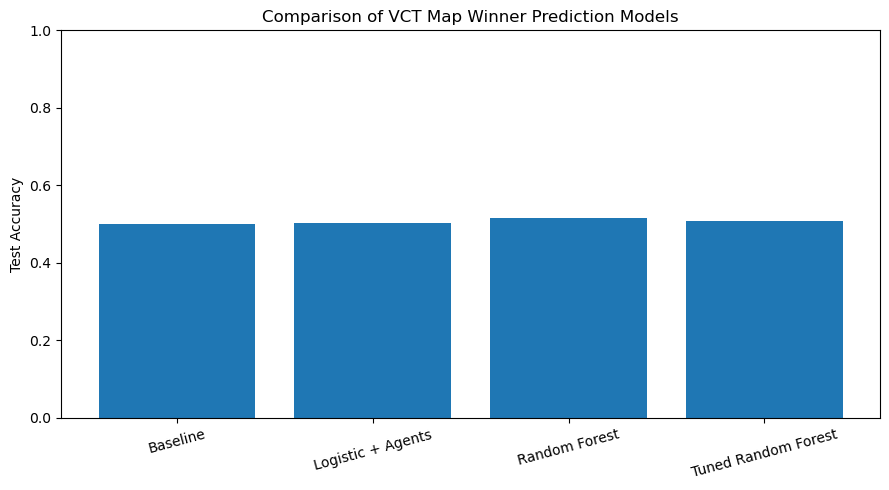

In [59]:
import matplotlib.pyplot as plt

model_names = [
    "Baseline",
    "Logistic + Agents",
    "Random Forest",
    "Tuned Random Forest"
]

accuracies = [
    baseline_acc,
    improved_acc,
    rf_accuracy,
    accuracy_score(y_test_improved, y_pred_tuned)
]

plt.figure(figsize=(9, 5))
plt.bar(model_names, accuracies)
plt.ylabel("Test Accuracy")
plt.title("Comparison of VCT Map Winner Prediction Models")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

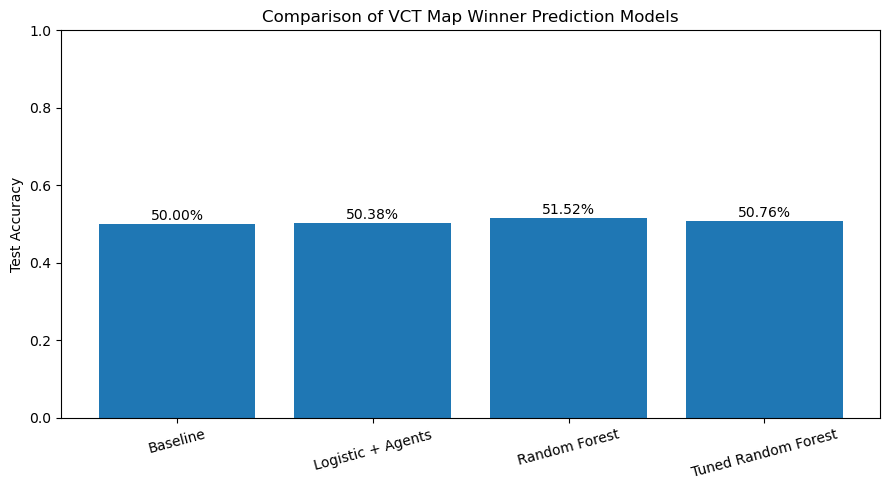

In [60]:
plt.figure(figsize=(9, 5))

bars = plt.bar(model_names, accuracies)

plt.ylabel("Test Accuracy")
plt.title("Comparison of VCT Map Winner Prediction Models")
plt.ylim(0, 1)
plt.xticks(rotation=15)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.01,
        f"{accuracy:.2%}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [61]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_improved.columns
).sort_values(ascending=False)

feature_importance.head(15)

A_yoru               0.015483
A_neon               0.015178
Stage_Playoffs       0.014852
B_sova               0.014832
A_breach             0.014830
B_fade               0.014655
B_yoru               0.014626
Team B_G2 Esports    0.014618
Stage_Group Stage    0.014602
A_fade               0.014578
B_kayo               0.014232
B_omen               0.014038
B_cypher             0.013807
B_killjoy            0.013674
Match Type_Week 1    0.013275
dtype: float64

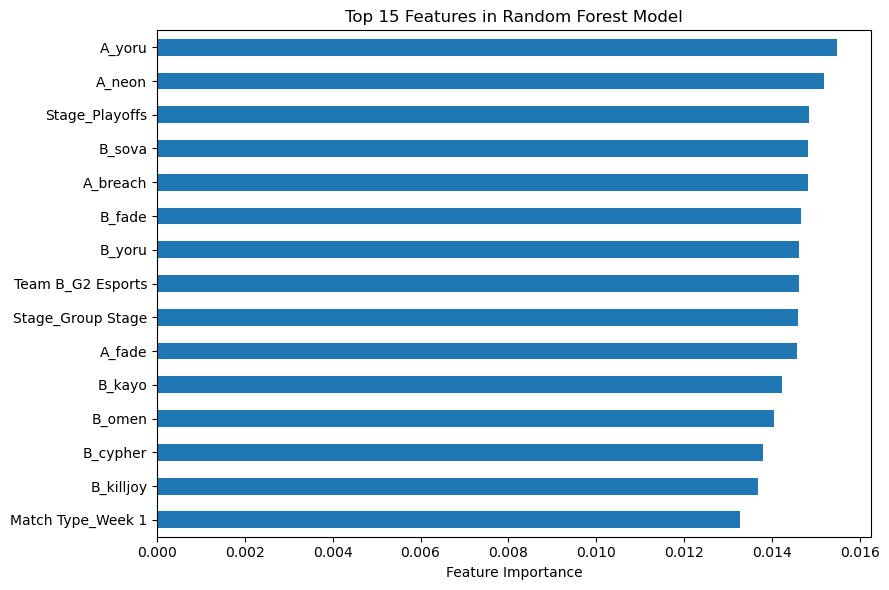

In [62]:
top_features = feature_importance.head(15).sort_values()

plt.figure(figsize=(9, 6))
top_features.plot(kind="barh")

plt.xlabel("Feature Importance")
plt.title("Top 15 Features in Random Forest Model")
plt.tight_layout()
plt.show()

In [63]:
sample_index = X_test_improved.index[0]

sample_row = df_model_agents.loc[sample_index]

predicted_label = rf_model.predict(
    X_test_improved.loc[[sample_index]]
)[0]

actual_label = y_test_improved.loc[sample_index]

print("Match:", sample_row["Match Name"])
print("Map:", sample_row["Map"])
print("Team A:", sample_row["Team A"])
print("Team B:", sample_row["Team B"])

print(
    "Predicted winner:",
    sample_row["Team A"] if predicted_label == 1 else sample_row["Team B"]
)

print(
    "Actual winner:",
    sample_row["Team A"] if actual_label == 1 else sample_row["Team B"]
)

Match: DRX vs NRG
Map: Haven
Team A: DRX
Team B: Mega Minors
Predicted winner: DRX
Actual winner: DRX


In [64]:
import joblib

model_package = {
    "model": rf_model,
    "feature_columns": X_improved.columns.tolist(),
    "teams": sorted(
        set(df_model_agents["Team A"].dropna()) |
        set(df_model_agents["Team B"].dropna())
    ),
    "maps": sorted(df_model_agents["Map"].dropna().unique().tolist()),
    "tournaments": sorted(df_model_agents["Tournament"].dropna().unique().tolist()),
    "stages": sorted(df_model_agents["Stage"].dropna().unique().tolist()),
    "match_types": sorted(df_model_agents["Match Type"].dropna().unique().tolist()),
    "agents": sorted(set(mlb_a.classes_) | set(mlb_b.classes_))
}

joblib.dump(model_package, "vct_map_prediction_model.joblib")

['vct_map_prediction_model.joblib']

In [65]:
saved_package = joblib.load("vct_map_prediction_model.joblib")

saved_model = saved_package["model"]

sample_features = X_test_improved.iloc[[0]].reindex(
    columns=saved_package["feature_columns"],
    fill_value=0
)

saved_prediction = saved_model.predict(sample_features)[0]

print("Saved model prediction:", saved_prediction)

Saved model prediction: 1


In [66]:
model_package["base_columns"] = X_base.columns.tolist()

model_package["agent_features_a"] = mlb_a.classes_.tolist()
model_package["agent_features_b"] = mlb_b.classes_.tolist()

model_package["feature_columns"] = X_improved.columns.tolist()
model_package["model"] = rf_model

joblib.dump(model_package, "vct_map_prediction_model.joblib")

print("Model package updated successfully!")

Model package updated successfully!


In [68]:
def predict_map_winner(
    team_a, team_b, map_name, tournament, stage, match_type,
    agents_a, agents_b
):
    input_data = pd.DataFrame(
        0,
        index=[0],
        columns=model_package["feature_columns"]
    )

    categories = {
        "Tournament": tournament,
        "Stage": stage,
        "Match Type": match_type,
        "Map": map_name,
        "Team A": team_a,
        "Team B": team_b
    }

    for name, value in categories.items():
        column = f"{name}_{value}"

        if column not in input_data.columns:
            raise ValueError(f"Unknown {name}: {value}")

        input_data.loc[0, column] = 1

    for agent in agents_a:
        column = f"A_{agent.strip()}"
        if column not in input_data.columns:
            raise ValueError(f"Unknown Team A agent: {agent}")
        input_data.loc[0, column] = 1

    for agent in agents_b:
        column = f"B_{agent.strip()}"
        if column not in input_data.columns:
            raise ValueError(f"Unknown Team B agent: {agent}")
        input_data.loc[0, column] = 1

    model = model_package["model"]
    prediction = model.predict(input_data)[0]

    class_index = list(model.classes_).index(1)
    probability = model.predict_proba(input_data)[0][class_index]

    winner = team_a if prediction == 1 else team_b

    return {
        "predicted_winner": winner,
        "team_a_win_estimate": round(probability * 100, 2)
    }

In [69]:
sample_index = X_test_improved.index[0]
sample_row = df_model_agents.loc[sample_index]

match_filter = (
    (team_agents_2025["Tournament"] == sample_row["Tournament"]) &
    (team_agents_2025["Stage"] == sample_row["Stage"]) &
    (team_agents_2025["Match Type"] == sample_row["Match Type"]) &
    (team_agents_2025["Match Name"] == sample_row["Match Name"]) &
    (team_agents_2025["Map"] == sample_row["Map"])
)

agents_a = team_agents_2025.loc[
    match_filter & (team_agents_2025["Team"] == sample_row["Team A"]),
    "Agents"
].iloc[0].split(", ")

agents_b = team_agents_2025.loc[
    match_filter & (team_agents_2025["Team"] == sample_row["Team B"]),
    "Agents"
].iloc[0].split(", ")

result = predict_map_winner(
    team_a=sample_row["Team A"],
    team_b=sample_row["Team B"],
    map_name=sample_row["Map"],
    tournament=sample_row["Tournament"],
    stage=sample_row["Stage"],
    match_type=sample_row["Match Type"],
    agents_a=agents_a,
    agents_b=agents_b
)

print(result)

{'predicted_winner': 'DRX', 'team_a_win_estimate': np.float64(53.75)}
